il centroide è la media dei punti del gruppo. <br>
K numero di clsuters è in input.

Come determinare numero di K buono:<br> numero K minore possibile e anche inerzia migliore
Come valuter Clustering buono? Quanto i cluter sono compatti e quanto sono distanti tra di loro!<br>
il metodo K Means considera la loro compattezza (inerzia) NON la distanza.

In [71]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels as sm
from sklearn.preprocessing import MinMaxScaler

# Load the input data set
input_dataframe = pd.read_csv('data/comuni_dashboard_df.csv')

input_dataframe

,Codice Comune,Nome,Trend Incidenti,p-value,Incidentix1000abitanti,Incidentixkm²,Gravità Incidenti,Ampiezza demografica - Theme,Ampiezza demografica - SubTheme
0,1001,Agliè,-0.053404,0.048158,1.53,0.31,1.66,<10k,2k-3k
1,1002,Airasca,-0.187463,0.000016,3.08,0.72,1.61,<10k,3k-5k
2,1003,Ala di Stura,0.050023,0.100870,0.50,0.00,1.60,<10k,< 500
3,1004,Albiano d'Ivrea,-0.086664,0.051387,2.68,0.39,1.67,<10k,1k-2k
4,1005,Alice Superiore,-0.089647,0.187080,1.72,0.16,1.83,<10k,500-999
...,...,...,...,...,...,...,...,...,...
8569,111103,Villaputzu,-0.009250,0.940114,1.46,0.04,1.64,<10k,3k-5k
8570,111104,Villasalto,-0.099536,0.790368,2.35,0.02,1.42,<10k,1k-2k
8571,111105,Villasimius,0.086857,0.482700,1.62,0.10,1.37,<10k,3k-5k
8572,111106,Villasor,-0.094643,0.230676,2.03,0.16,1.65,<10k,5k-10k


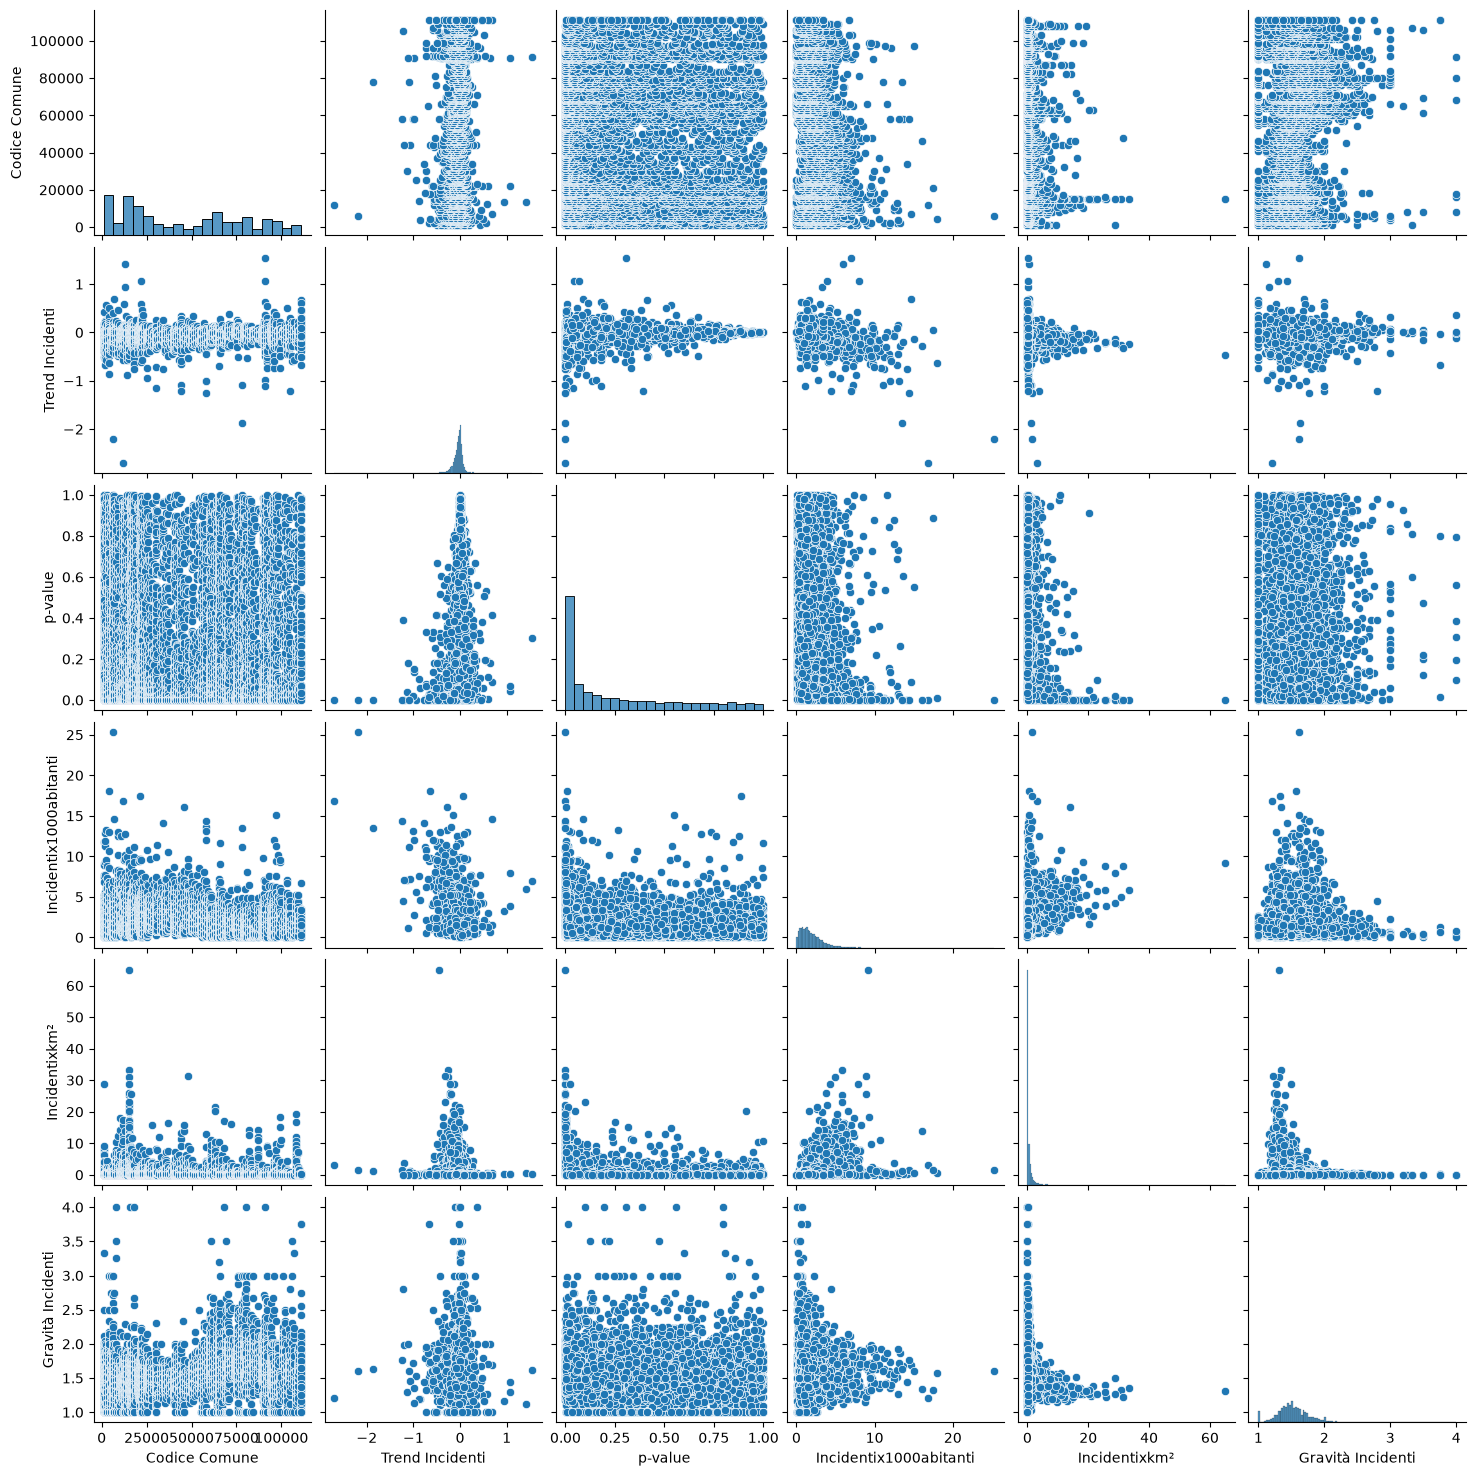

In [72]:
sns.pairplot(input_dataframe)
# così nessuna coppia di variabili si presta al clustering.

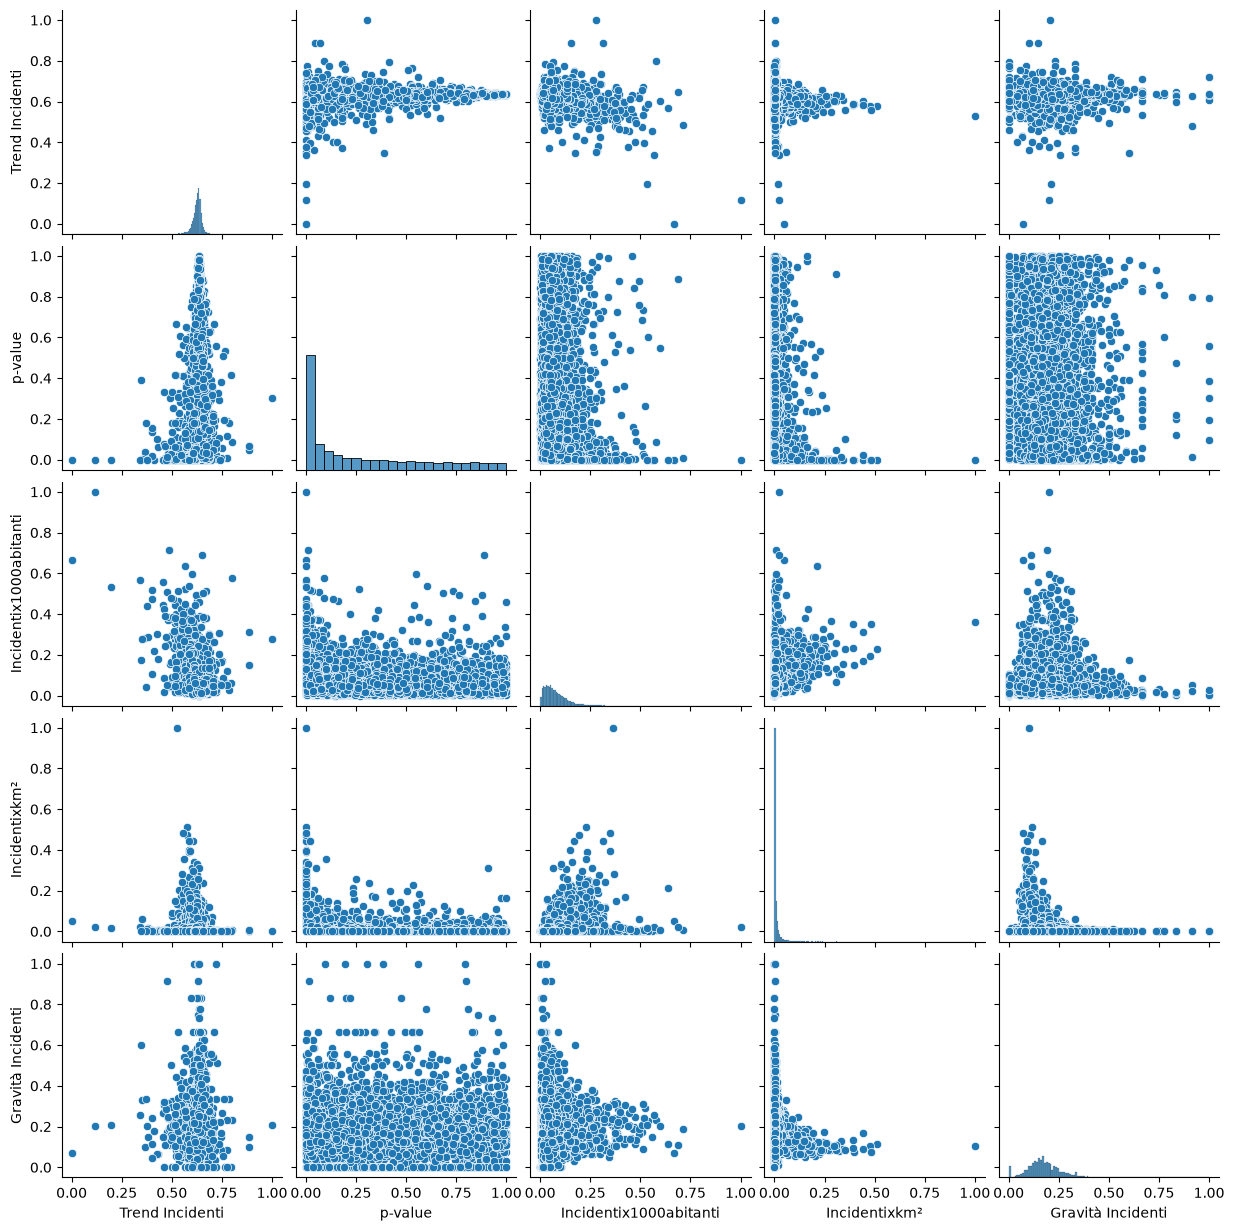

In [73]:
# normalize data
scale_norm = MinMaxScaler()
colonne_numeriche = ['Trend Incidenti', 'p-value', 'Incidentix1000abitanti', 'Incidentixkm²', 'Gravità Incidenti']
scaled_dataframe = pd.DataFrame(scale_norm.fit_transform(input_dataframe[colonne_numeriche].dropna()), columns=colonne_numeriche)

sns.pairplot(scaled_dataframe)

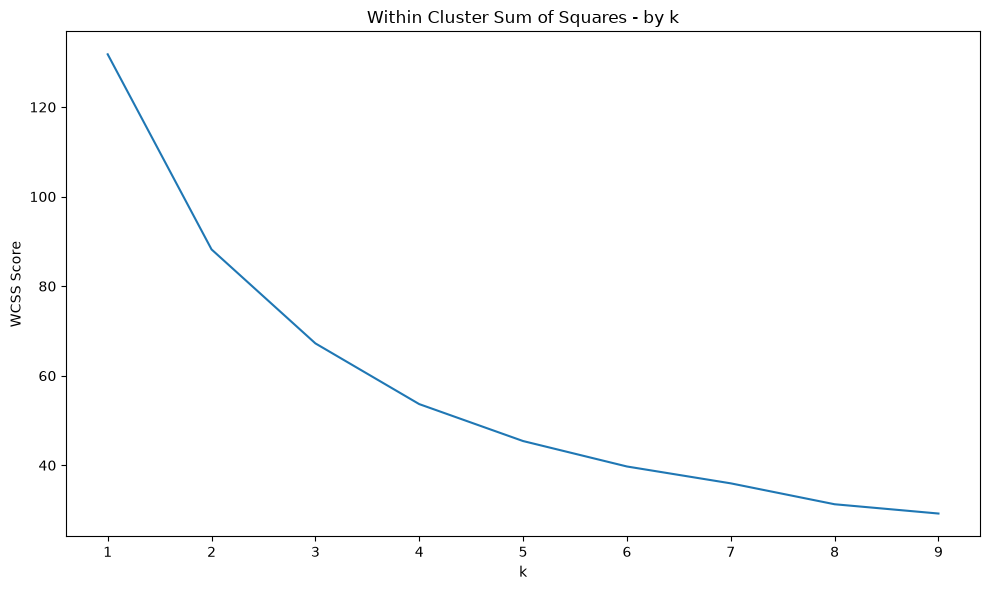

In [80]:
from sklearn.cluster import KMeans

k_values = list(range(1,10))
wcss_list = []

for k in k_values:
	kmeans = KMeans(n_clusters = k, random_state=42)
	kmeans.fit(scaled_dataframe[['Trend Incidenti','Incidentix1000abitanti', 'Incidentixkm²', 'Gravità Incidenti']])
	wcss_list.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(k_values, wcss_list)
plt.title("Within Cluster Sum of Squares - by k")
plt.xlabel("k")
plt.ylabel("WCSS Score")
plt.tight_layout()
plt.show()

In [78]:
from sklearn.cluster import KMeans

kmeans2 = KMeans(n_clusters=2, random_state=42)
kmeans2_result = kmeans2.fit_predict(scaled_dataframe[['Trend Incidenti','Incidentix1000abitanti', 'Incidentixkm²', 'Gravità Incidenti']].dropna())

kmeans3 = KMeans(n_clusters=3, random_state=42)
kmeans3_result = kmeans3.fit_predict(scaled_dataframe[['Trend Incidenti','Incidentix1000abitanti', 'Incidentixkm²', 'Gravità Incidenti']].dropna())

kmeans4 = KMeans(n_clusters=4, random_state=42)
kmeans4_result = kmeans4.fit_predict(scaled_dataframe[['Trend Incidenti','Incidentix1000abitanti', 'Incidentixkm²', 'Gravità Incidenti']].dropna())

kmeans5 = KMeans(n_clusters=5, random_state=42)
kmeans5_result = kmeans5.fit_predict(scaled_dataframe[['Trend Incidenti','Incidentix1000abitanti', 'Incidentixkm²', 'Gravità Incidenti']].dropna())

kmeans6 = KMeans(n_clusters=6, random_state=42)
kmeans6_result = kmeans6.fit_predict(scaled_dataframe[['Trend Incidenti','Incidentix1000abitanti', 'Incidentixkm²', 'Gravità Incidenti']].dropna())

kmeans7 = KMeans(n_clusters=7, random_state=42)
kmeans7_result = kmeans7.fit_predict(scaled_dataframe[['Trend Incidenti','Incidentix1000abitanti', 'Incidentixkm²', 'Gravità Incidenti']].dropna())

kmeans8 = KMeans(n_clusters=8, random_state=42)
kmeans8_result = kmeans8.fit_predict(scaled_dataframe[['Trend Incidenti','Incidentix1000abitanti', 'Incidentixkm²', 'Gravità Incidenti']].dropna())

kmeans9 = KMeans(n_clusters=9, random_state=42)
kmeans9_result = kmeans9.fit_predict(scaled_dataframe[['Trend Incidenti','Incidentix1000abitanti', 'Incidentixkm²', 'Gravità Incidenti']].dropna())

In [79]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score

# Silhouette
print("Silhouette score for clustering 2", silhouette_score(scaled_dataframe, kmeans2_result))
print("Silhouette score for clustering 3", silhouette_score(scaled_dataframe, kmeans3_result))
print("Silhouette score for clustering 4", silhouette_score(scaled_dataframe, kmeans4_result))
print("Silhouette score for clustering 5", silhouette_score(scaled_dataframe, kmeans5_result))
print("Silhouette score for clustering 6", silhouette_score(scaled_dataframe, kmeans6_result))
print("Silhouette score for clustering 7", silhouette_score(scaled_dataframe, kmeans7_result))
print("Silhouette score for clustering 8", silhouette_score(scaled_dataframe, kmeans8_result))
print("Silhouette score for clustering 9", silhouette_score(scaled_dataframe, kmeans9_result))


# Calinski-Harabasz
print("Calinski-harabasz index for clustering 2", calinski_harabasz_score(scaled_dataframe, kmeans3_result))
print("Calinski-harabasz index for clustering 3", calinski_harabasz_score(scaled_dataframe, kmeans4_result))
print("Calinski-harabasz index for clustering 4", calinski_harabasz_score(scaled_dataframe, kmeans5_result))
print("Calinski-harabasz index for clustering 5", calinski_harabasz_score(scaled_dataframe, kmeans6_result))
print("Calinski-harabasz index for clustering 6", calinski_harabasz_score(scaled_dataframe, kmeans7_result))
print("Calinski-harabasz index for clustering 7", calinski_harabasz_score(scaled_dataframe, kmeans8_result))
print("Calinski-harabasz index for clustering 8", calinski_harabasz_score(scaled_dataframe, kmeans9_result))
print("Calinski-harabasz index for clustering 9", calinski_harabasz_score(scaled_dataframe, kmeans9_result))


Silhouette score for clustering 2 0.1057094842892511
Silhouette score for clustering 3 0.025903688816616175
Silhouette score for clustering 4 0.01050109821129554
Silhouette score for clustering 5 -0.0017579073788742475
Silhouette score for clustering 6 -0.02238175443590323
Silhouette score for clustering 7 -0.03327678012730602
Silhouette score for clustering 8 -0.04525366223850995
Silhouette score for clustering 9 -0.05092190753392683
Calinski-harabasz index for clustering 2 547.1286587134819
Calinski-harabasz index for clustering 3 405.9271075100679
Calinski-harabasz index for clustering 4 346.58587572196865
Calinski-harabasz index for clustering 5 326.5468900469121
Calinski-harabasz index for clustering 6 284.72585325336337
Calinski-harabasz index for clustering 7 244.1398439805209
Calinski-harabasz index for clustering 8 219.16613153033808
Calinski-harabasz index for clustering 9 219.16613153033808


Inerzia mi suggerisce 2 cluster